# Image Data Analysis

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
import os
import cv2
from PIL import Image
import shutil

## DATA LOADING

In [3]:
imgData="/kaggle/input/datasets/anaghachoudhari/pcos-detection-using-ultrasound-images"

for root, dirs, files in os.walk(imgData):
    print(root)
    print("Folders:", dirs)
    print("Number of files:", len(files))
    print("-"*50)

/kaggle/input/datasets/anaghachoudhari/pcos-detection-using-ultrasound-images
Folders: ['data']
Number of files: 0
--------------------------------------------------
/kaggle/input/datasets/anaghachoudhari/pcos-detection-using-ultrasound-images/data
Folders: ['test', 'train']
Number of files: 0
--------------------------------------------------
/kaggle/input/datasets/anaghachoudhari/pcos-detection-using-ultrasound-images/data/test
Folders: ['infected', 'notinfected']
Number of files: 0
--------------------------------------------------
/kaggle/input/datasets/anaghachoudhari/pcos-detection-using-ultrasound-images/data/test/infected
Folders: []
Number of files: 787
--------------------------------------------------
/kaggle/input/datasets/anaghachoudhari/pcos-detection-using-ultrasound-images/data/test/notinfected
Folders: []
Number of files: 1145
--------------------------------------------------
/kaggle/input/datasets/anaghachoudhari/pcos-detection-using-ultrasound-images/data/train
Fold

In [4]:
imgData="/kaggle/input/datasets/anaghachoudhari/pcos-detection-using-ultrasound-images"

for root, dirs, files in os.walk(imgData):
    print(root)
    print("Folders:", dirs)
    print("Number of files:", len(files))
    print("-"*50)

/kaggle/input/datasets/anaghachoudhari/pcos-detection-using-ultrasound-images
Folders: ['data']
Number of files: 0
--------------------------------------------------
/kaggle/input/datasets/anaghachoudhari/pcos-detection-using-ultrasound-images/data
Folders: ['test', 'train']
Number of files: 0
--------------------------------------------------
/kaggle/input/datasets/anaghachoudhari/pcos-detection-using-ultrasound-images/data/test
Folders: ['infected', 'notinfected']
Number of files: 0
--------------------------------------------------
/kaggle/input/datasets/anaghachoudhari/pcos-detection-using-ultrasound-images/data/test/infected
Folders: []
Number of files: 787
--------------------------------------------------
/kaggle/input/datasets/anaghachoudhari/pcos-detection-using-ultrasound-images/data/test/notinfected
Folders: []
Number of files: 1145
--------------------------------------------------
/kaggle/input/datasets/anaghachoudhari/pcos-detection-using-ultrasound-images/data/train
Fold

In [5]:
base_path = "/kaggle/input/datasets/anaghachoudhari/pcos-detection-using-ultrasound-images/data/train"

for cls in ["infected", "notinfected"]:
    class_path = os.path.join(base_path, cls)

    image_name = os.listdir(class_path)[0]
    image_path = os.path.join(class_path, image_name)

    img = Image.open(image_path)

    print(cls, ":", img.size)

infected : (343, 343)
notinfected : (850, 578)


## EDA

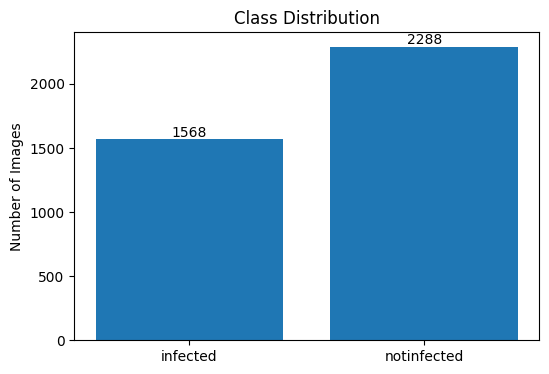

In [6]:
classes = ['infected', 'notinfected']
counts = [781+787, 1143+1145]

plt.figure(figsize=(6,4))
plt.bar(classes, counts)
plt.title("Class Distribution")
plt.ylabel("Number of Images")

for i,v in enumerate(counts):
    plt.text(i, v+20, str(v), ha='center')

plt.show()

In [7]:
train_path = "/kaggle/input/datasets/anaghachoudhari/pcos-detection-using-ultrasound-images/data/train"

widths = []
heights = []

for cls in ["infected","notinfected"]:
    class_path = os.path.join(train_path, cls)

    for img_name in os.listdir(class_path):
        img = Image.open(os.path.join(class_path, img_name))
        w,h = img.size

        widths.append(w)
        heights.append(h)

print("Minimum width :", min(widths))
print("Maximum width :", max(widths))

print("Minimum height:", min(heights))
print("Maximum height:", max(heights))

Minimum width : 225
Maximum width : 984
Minimum height: 160
Maximum height: 848


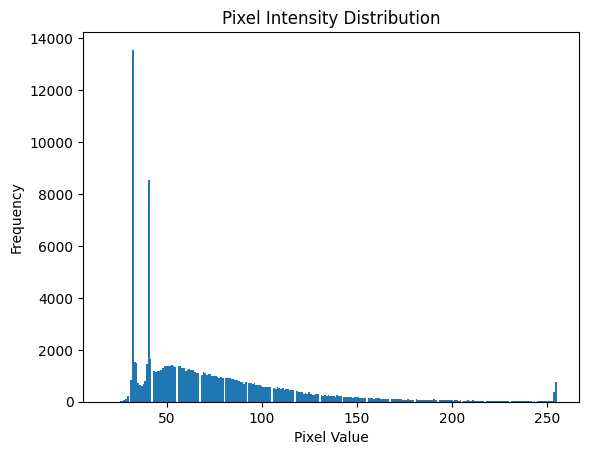

In [8]:
sample_path = os.path.join(
    train_path,
    "infected",
    os.listdir(os.path.join(train_path,"infected"))[0]
)

img = cv2.imread(sample_path,0)

plt.hist(img.ravel(), bins=256)
plt.title("Pixel Intensity Distribution")
plt.xlabel("Pixel Value")
plt.ylabel("Frequency")
plt.show()

In [9]:
train_dir = "/kaggle/input/datasets/anaghachoudhari/pcos-detection-using-ultrasound-images/data/train"

bad_files = []

for cls in ["infected", "notinfected"]:
    class_path = os.path.join(train_dir, cls)

    for file in os.listdir(class_path):
        path = os.path.join(class_path, file)

        try:
            img = Image.open(path)
            img.verify()

        except Exception as e:
            bad_files.append(path)
            print("Bad file:", path)

print("\nTotal bad files:", len(bad_files))


Total bad files: 0


In [10]:
test_dir = "/kaggle/input/datasets/anaghachoudhari/pcos-detection-using-ultrasound-images/data/test"

bad_files = []

for cls in ["infected", "notinfected"]:
    class_path = os.path.join(test_dir, cls)

    for file in os.listdir(class_path):
        path = os.path.join(class_path, file)

        try:
            img = Image.open(path)
            img.verify()

        except Exception:
            bad_files.append(path)

print("Bad files:", len(bad_files))

Bad files: 10


In [11]:
for cls in ["infected","notinfected"]:
    class_path = os.path.join(train_dir, cls)

    print("\n", cls)
    print(os.listdir(class_path)[:20])


 infected
['img1.jpg', 'img10.jpg', 'img2.jpg', 'img3.jpg', 'img4.jpg', 'img5.jpg', 'img6.jpg', 'img7.jpg', 'img8.jpg', 'img_0_1023.jpg', 'img_0_1033.jpg', 'img_0_1071.jpg', 'img_0_1075.jpg', 'img_0_1079.jpg', 'img_0_1083.jpg', 'img_0_1087.jpg', 'img_0_1088.jpg', 'img_0_1099.jpg', 'img_0_113.jpg', 'img_0_1130.jpg']

 notinfected
['Copy of img_0_9989.jpg', 'img1.jpeg', 'img2.png', 'img3.jpg', 'img4.jpg', 'img_0_0.jpg', 'img_0_100.jpg', 'img_0_1012.jpg', 'img_0_1015.jpg', 'img_0_1020.jpg', 'img_0_1022.jpg', 'img_0_1027.jpg', 'img_0_103.jpg', 'img_0_1041.jpg', 'img_0_1050.jpg', 'img_0_1074.jpg', 'img_0_1081.jpg', 'img_0_1082.jpg', 'img_0_1083.jpg', 'img_0_1084.jpg']


In [12]:
test_dir = "/kaggle/input/datasets/anaghachoudhari/pcos-detection-using-ultrasound-images/data/test"

bad_files = []

for cls in ["infected", "notinfected"]:
    class_path = os.path.join(test_dir, cls)

    for file in os.listdir(class_path):
        path = os.path.join(class_path, file)

        try:
            img = Image.open(path)
            img.verify()

        except Exception as e:
            bad_files.append(path)
            print(path)

print("\nTotal bad files:", len(bad_files))

/kaggle/input/datasets/anaghachoudhari/pcos-detection-using-ultrasound-images/data/test/infected/OIP.jpg
/kaggle/input/datasets/anaghachoudhari/pcos-detection-using-ultrasound-images/data/test/infected/R.jpg
/kaggle/input/datasets/anaghachoudhari/pcos-detection-using-ultrasound-images/data/test/infected/WhatsApp Image 2022-04-01 at 3.49.22 PM.jpeg
/kaggle/input/datasets/anaghachoudhari/pcos-detection-using-ultrasound-images/data/test/infected/WhatsApp Image 2022-04-01 at 3.49.45 PM.jpeg
/kaggle/input/datasets/anaghachoudhari/pcos-detection-using-ultrasound-images/data/test/infected/WhatsApp Image 2022-04-01 at 3.50.05 PM.jpeg
/kaggle/input/datasets/anaghachoudhari/pcos-detection-using-ultrasound-images/data/test/infected/WhatsApp Image 2022-04-01 at 3.50.20 PM.jpeg
/kaggle/input/datasets/anaghachoudhari/pcos-detection-using-ultrasound-images/data/test/notinfected/OIP (1).jpg
/kaggle/input/datasets/anaghachoudhari/pcos-detection-using-ultrasound-images/data/test/notinfected/WhatsApp Ima

In [13]:
src_base = "/kaggle/input/datasets/anaghachoudhari/pcos-detection-using-ultrasound-images/data"
dst_base = "/kaggle/working/clean_data"

os.makedirs(dst_base, exist_ok=True)

for split in ["train", "test"]:
    for cls in ["infected", "notinfected"]:

        src_dir = os.path.join(src_base, split, cls)
        dst_dir = os.path.join(dst_base, split, cls)

        os.makedirs(dst_dir, exist_ok=True)

        copied = 0
        skipped = 0

        for file in os.listdir(src_dir):

            src_file = os.path.join(src_dir, file)

            try:
                img = Image.open(src_file)
                img = img.convert("RGB")

                shutil.copy2(src_file,
                             os.path.join(dst_dir, file))

                copied += 1

            except:
                skipped += 1

        print(f"{split}/{cls}")
        print("Copied:", copied)
        print("Skipped:", skipped)
        print("-"*30)

train/infected
Copied: 781
Skipped: 0
------------------------------
train/notinfected
Copied: 1143
Skipped: 0
------------------------------
test/infected
Copied: 781
Skipped: 6
------------------------------
test/notinfected
Copied: 1141
Skipped: 4
------------------------------


## MODEL TRAINING

In [14]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D
from tensorflow.keras.layers import MaxPooling2D
from tensorflow.keras.layers import Flatten
from tensorflow.keras.layers import Dense
from tensorflow.keras.layers import Dropout

cnn = Sequential()

cnn.add(Conv2D(32,(3,3),
               activation='relu',
               input_shape=(224,224,3)))

cnn.add(MaxPooling2D(2,2))

cnn.add(Conv2D(64,(3,3),activation='relu'))
cnn.add(MaxPooling2D(2,2))

cnn.add(Conv2D(128,(3,3),activation='relu'))
cnn.add(MaxPooling2D(2,2))

cnn.add(Flatten())

cnn.add(Dense(128,activation='relu'))
cnn.add(Dropout(0.5))

cnn.add(Dense(1,activation='sigmoid'))

cnn.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

cnn.summary()

2026-11-13 17:29:12.907880: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1794590953.244565     116 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1794590953.350603     116 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1794590954.191616     116 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1794590954.191671     116 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1794590954.191674     116 computation_placer.cc:177] computation placer alr

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 222, 222, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 111, 111, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 109, 109, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 54, 54, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 52, 52, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 26, 26, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 86528)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │    11,075,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 11,169,089 (42.61 MB)

 Trainable params: 11,169,089 (42.61 MB)

 Non-trainable params: 0 (0.00 B)

In [15]:
train_dir = "/kaggle/working/clean_data/train"
test_dir = "/kaggle/working/clean_data/test"

In [16]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator
IMG_SIZE = (224,224)

train_datagen = ImageDataGenerator(
    rescale=1./255,
    rotation_range=15,
    zoom_range=0.15,
    width_shift_range=0.1,
    height_shift_range=0.1,
    horizontal_flip=True
)

test_datagen = ImageDataGenerator(
    rescale=1./255
)

train_generator = train_datagen.flow_from_directory(
    train_dir,
    target_size=IMG_SIZE,
    batch_size=32,
    class_mode='binary'
)

test_generator = test_datagen.flow_from_directory(
    test_dir,
    target_size=IMG_SIZE,
    batch_size=32,
    class_mode='binary',
    shuffle=False
)

Found 1924 images belonging to 2 classes.
Found 1922 images belonging to 2 classes.


In [17]:
from tensorflow.keras.callbacks import EarlyStopping

early_stop = EarlyStopping(
    monitor='val_loss',
    patience=5,
    restore_best_weights=True
)

history = cnn.fit(
    train_generator,
    validation_data=test_generator,
    epochs=100,
    callbacks=[early_stop]
)

Epoch 1/100
61/61 ━━━━━━━━━━━━━━━━━━━━ 133s 2s/step - accuracy: 0.8841 - loss: 0.3169 - val_accuracy: 0.9979 - val_loss: 0.0208
Epoch 2/100
61/61 ━━━━━━━━━━━━━━━━━━━━ 131s 2s/step - accuracy: 0.9828 - loss: 0.0482 - val_accuracy: 0.9990 - val_loss: 0.0080
Epoch 3/100
61/61 ━━━━━━━━━━━━━━━━━━━━ 134s 2s/step - accuracy: 0.9865 - loss: 0.0385 - val_accuracy: 1.0000 - val_loss: 0.0061
Epoch 4/100
61/61 ━━━━━━━━━━━━━━━━━━━━ 150s 2s/step - accuracy: 0.9990 - loss: 0.0101 - val_accuracy: 1.0000 - val_loss: 1.5036e-04
Epoch 5/100
61/61 ━━━━━━━━━━━━━━━━━━━━ 152s 2s/step - accuracy: 0.9964 - loss: 0.0100 - val_accuracy: 1.0000 - val_loss: 6.9517e-04
Epoch 6/100
61/61 ━━━━━━━━━━━━━━━━━━━━ 146s 2s/step - accuracy: 0.9974 - loss: 0.0105 - val_accuracy: 1.0000 - val_loss: 1.7739e-04
Epoch 7/100
61/61 ━━━━━━━━━━━━━━━━━━━━ 129s 2s/step - accuracy: 1.0000 - loss: 0.0015 - val_accuracy: 1.0000 - val_loss: 1.3111e-04
Epoch 8/100
61/61 ━━━━━━━━━━━━━━━━━━━━ 141s 2s/step - accuracy: 0.9938 - loss: 0.0194 - 

In [18]:
test_loss, test_acc = cnn.evaluate(test_generator)

print("Test Accuracy:", test_acc)

61/61 ━━━━━━━━━━━━━━━━━━━━ 30s 492ms/step - accuracy: 1.0000 - loss: 6.6633e-06
Test Accuracy: 1.0


In [19]:
y_pred = cnn.predict(test_generator)
y_pred = (y_pred > 0.5).astype(int)

y_true = test_generator.classes

61/61 ━━━━━━━━━━━━━━━━━━━━ 30s 487ms/step


In [20]:
from sklearn.metrics import classification_report, confusion_matrix
# Classification Report
report = classification_report(y_true, y_pred, output_dict=True)
report_df = pd.DataFrame(report).transpose()

print("📊 Classification Report")
display(report_df.style.background_gradient(cmap="Blues").format("{:.3f}"))


📊 Classification Report


,precision,recall,f1-score,support
0,1.000,1.000,1.000,781.000
1,1.000,1.000,1.000,1141.000
accuracy,1.000,1.000,1.000,1.000
macro avg,1.000,1.000,1.000,1922.000
weighted avg,1.000,1.000,1.000,1922.000


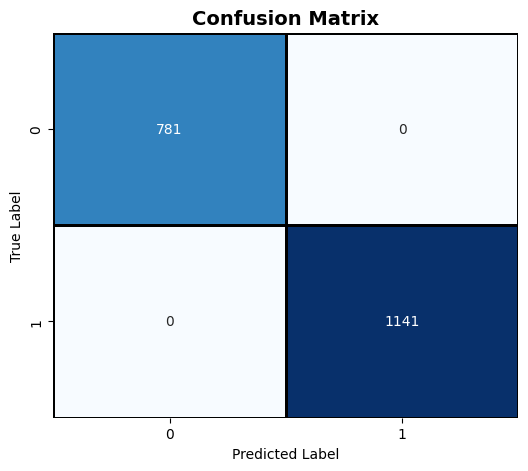

In [21]:
# Confusion Matrix
cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(6,5))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    cbar=False,
    linewidths=1,
    linecolor='black'
)

plt.title("Confusion Matrix", fontsize=14, fontweight='bold')
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.show()

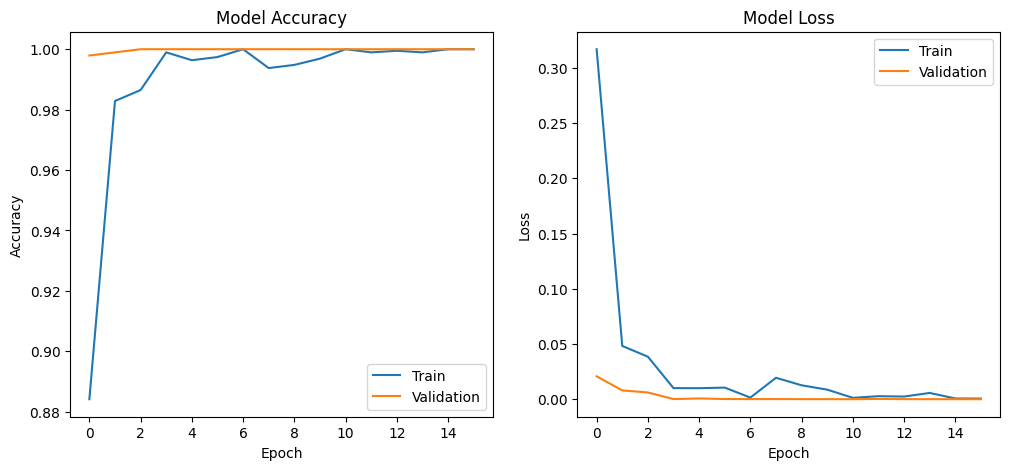

In [22]:
plt.figure(figsize=(12,5))

plt.subplot(1,2,1)
plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy'])
plt.title('Model Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend(['Train','Validation'])

plt.subplot(1,2,2)
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])
plt.title('Model Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend(['Train','Validation'])

plt.show()

In [23]:
train_inf = set(os.listdir("/kaggle/working/clean_data/train/infected"))
test_inf = set(os.listdir("/kaggle/working/clean_data/test/infected"))

common_inf = train_inf.intersection(test_inf)

print("Common infected images:", len(common_inf))
print(list(common_inf)[:20])

Common infected images: 781
['img_0_8608.jpg', 'img_0_1410.jpg', 'img_0_2412.jpg', 'img_0_6995.jpg', 'img_0_7175.jpg', 'img_0_5863.jpg', 'img_0_3244.jpg', 'img_0_3327.jpg', 'img_0_7818.jpg', 'img_0_9647.jpg', 'img_0_4743.jpg', 'img_0_1589.jpg', 'img_0_9446.jpg', 'img_0_7795.jpg', 'img_0_367.jpg', 'img_0_3626.jpg', 'img_0_9158.jpg', 'img_0_3218.jpg', 'img_0_9842.jpg', 'img_0_6496.jpg']


In [24]:
train_non = set(os.listdir("/kaggle/working/clean_data/train/notinfected"))
test_non = set(os.listdir("/kaggle/working/clean_data/test/notinfected"))

common_non = train_non.intersection(test_non)

print("Common noninfected images:", len(common_non))
print(list(common_non)[:20])

Common noninfected images: 1141
['img_0_3762.jpg', 'img_0_8740.jpg', 'img_0_1950.jpg', 'img_0_5255.jpg', 'img_0_4172.jpg', 'img_0_2412.jpg', 'img_0_8250.jpg', 'img_0_2208.jpg', 'img_0_1693.jpg', 'img_0_8814.jpg', 'img_0_114.jpg', 'img_0_6637.jpg', 'img_0_294.jpg', 'img_0_7403.jpg', 'img_0_7227.jpg', 'img_0_3810.jpg', 'img_0_4990.jpg', 'img_0_7466.jpg', 'img_0_1224.jpg', 'img_0_5636.jpg']


In [25]:
print(len(os.listdir("/kaggle/working/clean_data/train/infected")))
print(len(os.listdir("/kaggle/working/clean_data/train/notinfected")))
print(len(os.listdir("/kaggle/working/clean_data/test/infected")))
print(len(os.listdir("/kaggle/working/clean_data/test/notinfected")))

781
1143
781
1141


In [26]:
base = "/kaggle/working/clean_data"

infected_files = []
notinfected_files = []

for split in ["train", "test"]:
    
    infected_path = os.path.join(base, split, "infected")
    notinfected_path = os.path.join(base, split, "notinfected")

    infected_files.extend(
        [os.path.join(infected_path, f) for f in os.listdir(infected_path)]
    )

    notinfected_files.extend(
        [os.path.join(notinfected_path, f) for f in os.listdir(notinfected_path)]
    )

print("Total infected:", len(infected_files))
print("Total notinfected:", len(notinfected_files))

Total infected: 1562
Total notinfected: 2284


In [27]:
infected_unique = list(set(infected_files))
notinfected_unique = list(set(notinfected_files))

print("Unique infected:", len(infected_unique))
print("Unique notinfected:", len(notinfected_unique))

Unique infected: 1562
Unique notinfected: 2284


In [28]:
train_inf = set(os.listdir("/kaggle/working/clean_data/train/infected"))
test_inf = set(os.listdir("/kaggle/working/clean_data/test/infected"))

print("Common infected:", len(train_inf.intersection(test_inf)))

train_non = set(os.listdir("/kaggle/working/clean_data/train/notinfected"))
test_non = set(os.listdir("/kaggle/working/clean_data/test/notinfected"))

print("Common noninfected:", len(train_non.intersection(test_non)))

Common infected: 781
Common noninfected: 1141


In [29]:
import hashlib

train_file = "/kaggle/working/clean_data/train/infected/img_0_1944.jpg"
test_file = "/kaggle/working/clean_data/test/infected/img_0_1944.jpg"

def md5(fname):
    with open(fname, "rb") as f:
        return hashlib.md5(f.read()).hexdigest()

print("Train hash:", md5(train_file))
print("Test hash :", md5(test_file))
print("Same file?:", md5(train_file) == md5(test_file))

Train hash: 3b40c5a35b563c5d94c4a9ca0e5f9eaa
Test hash : 3b40c5a35b563c5d94c4a9ca0e5f9eaa
Same file?: True


The perfect classification results achieved by the CNN model should be interpreted with caution because the testing dataset contains duplicate images from the training dataset. For a reliable evaluation, the dataset should be re-split so that no image appears in both training and testing sets.

In [30]:
from sklearn.model_selection import train_test_split

source_base = "/kaggle/working/clean_data/train"
new_base = "/kaggle/working/fresh_split"

classes = ["infected", "notinfected"]

for cls in classes:

    src = os.path.join(source_base, cls)

    images = [
        os.path.join(src, f)
        for f in os.listdir(src)
        if f.lower().endswith((".jpg", ".jpeg", ".png"))
    ]

    train_imgs, test_imgs = train_test_split(
        images,
        test_size=0.2,
        random_state=42,
        shuffle=True
    )

    os.makedirs(os.path.join(new_base, "train", cls), exist_ok=True)
    os.makedirs(os.path.join(new_base, "test", cls), exist_ok=True)

    for img in train_imgs:
        shutil.copy(img, os.path.join(new_base, "train", cls))

    for img in test_imgs:
        shutil.copy(img, os.path.join(new_base, "test", cls))

    print(cls)
    print("Train:", len(train_imgs))
    print("Test :", len(test_imgs))

infected
Train: 624
Test : 157
notinfected
Train: 914
Test : 229


In [31]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator

IMG_SIZE = (224,224)

train_dir = "/kaggle/working/fresh_split/train"
test_dir = "/kaggle/working/fresh_split/test"

train_datagen = ImageDataGenerator(
    rescale=1./255,
    rotation_range=15,
    zoom_range=0.15,
    width_shift_range=0.1,
    height_shift_range=0.1,
    horizontal_flip=True
)

test_datagen = ImageDataGenerator(
    rescale=1./255
)

train_generator = train_datagen.flow_from_directory(
    train_dir,
    target_size=IMG_SIZE,
    batch_size=32,
    class_mode='binary'
)

test_generator = test_datagen.flow_from_directory(
    test_dir,
    target_size=IMG_SIZE,
    batch_size=32,
    class_mode='binary',
    shuffle=False
)

Found 1538 images belonging to 2 classes.
Found 386 images belonging to 2 classes.


In [32]:
from tensorflow.keras.callbacks import EarlyStopping

early_stop = EarlyStopping(
    monitor='val_loss',
    patience=5,
    restore_best_weights=True
)

history = cnn.fit(
    train_generator,
    validation_data=test_generator,
    epochs=100,
    callbacks=[early_stop]
)

Epoch 1/100
49/49 ━━━━━━━━━━━━━━━━━━━━ 95s 2s/step - accuracy: 0.9987 - loss: 0.0014 - val_accuracy: 1.0000 - val_loss: 1.8167e-06
Epoch 2/100
49/49 ━━━━━━━━━━━━━━━━━━━━ 103s 2s/step - accuracy: 0.9948 - loss: 0.0120 - val_accuracy: 1.0000 - val_loss: 6.2337e-05
Epoch 3/100
49/49 ━━━━━━━━━━━━━━━━━━━━ 99s 2s/step - accuracy: 0.9980 - loss: 0.0053 - val_accuracy: 1.0000 - val_loss: 2.4595e-05
Epoch 4/100
49/49 ━━━━━━━━━━━━━━━━━━━━ 98s 2s/step - accuracy: 0.9980 - loss: 0.0061 - val_accuracy: 1.0000 - val_loss: 9.3749e-06
Epoch 5/100
49/49 ━━━━━━━━━━━━━━━━━━━━ 99s 2s/step - accuracy: 0.9987 - loss: 0.0034 - val_accuracy: 1.0000 - val_loss: 3.1454e-04
Epoch 6/100
49/49 ━━━━━━━━━━━━━━━━━━━━ 142s 2s/step - accuracy: 0.9961 - loss: 0.0148 - val_accuracy: 1.0000 - val_loss: 3.1688e-04


In [33]:
test_loss, test_acc = cnn.evaluate(test_generator)

print("Accuracy:", test_acc)

13/13 ━━━━━━━━━━━━━━━━━━━━ 6s 471ms/step - accuracy: 1.0000 - loss: 1.8167e-06
Accuracy: 1.0


In [34]:
y_pred = cnn.predict(test_generator)
y_pred = (y_pred > 0.5).astype(int)

y_true = test_generator.classes

13/13 ━━━━━━━━━━━━━━━━━━━━ 6s 476ms/step



📊 Classification Report


,precision,recall,f1-score,support
Class 0,1.00,1.00,1.00,157.00
Class 1,1.00,1.00,1.00,229.00
accuracy,1.00,1.00,1.00,1.00
macro avg,1.00,1.00,1.00,386.00
weighted avg,1.00,1.00,1.00,386.00


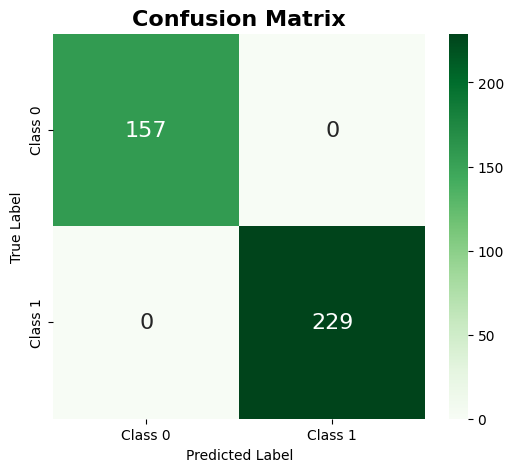

In [35]:
from sklearn.metrics import classification_report, confusion_matrix

# Classification Report
report = classification_report(
    y_true,
    y_pred,
    target_names=['Class 0', 'Class 1'],
    output_dict=True
)

report_df = pd.DataFrame(report).transpose()

print("\n📊 Classification Report")
display(report_df.style
        .background_gradient(cmap='Greens')
        .format("{:.2f}"))

# Confusion Matrix
cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(6,5))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Greens',
    xticklabels=['Class 0', 'Class 1'],
    yticklabels=['Class 0', 'Class 1'],
    annot_kws={"size":16}
)

plt.title("Confusion Matrix", fontsize=16, fontweight='bold')
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.show()

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 577ms/step


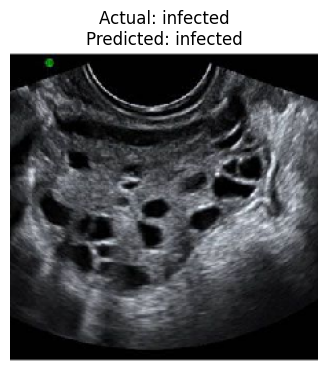

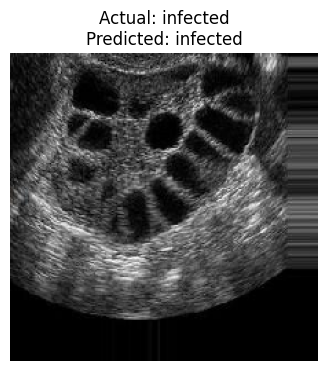

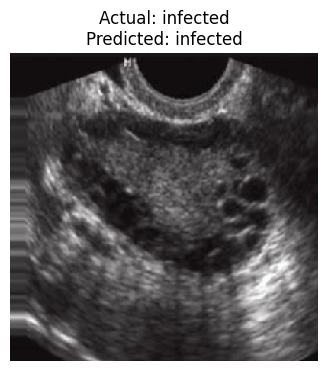

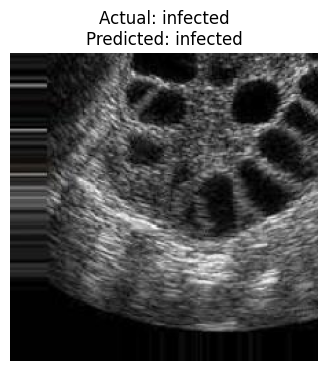

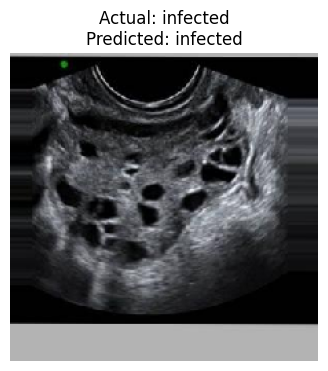

In [36]:
import matplotlib.pyplot as plt
import numpy as np

images, labels = next(test_generator)

preds = cnn.predict(images)

for i in range(5):

    plt.figure(figsize=(4,4))
    plt.imshow(images[i])

    actual = "infected" if labels[i] == 0 else "notinfected"
    predicted = "infected" if preds[i] < 0.5 else "notinfected"

    plt.title(f"Actual: {actual}\nPredicted: {predicted}")
    plt.axis("off")
    plt.show()

In [37]:
import hashlib
import os

infected_hashes = set()
duplicates = 0

folder = "/kaggle/working/clean_data/train/infected"

for file in os.listdir(folder):

    path = os.path.join(folder, file)

    with open(path, "rb") as f:
        h = hashlib.md5(f.read()).hexdigest()

    if h in infected_hashes:
        duplicates += 1
    else:
        infected_hashes.add(h)

print("Duplicate infected images:", duplicates)

Duplicate infected images: 2


In [38]:
preds = cnn.predict(test_generator)

print("Min prediction:", preds.min())
print("Max prediction:", preds.max())

13/13 ━━━━━━━━━━━━━━━━━━━━ 6s 490ms/step
Min prediction: 6.0700816e-36
Max prediction: 1.0


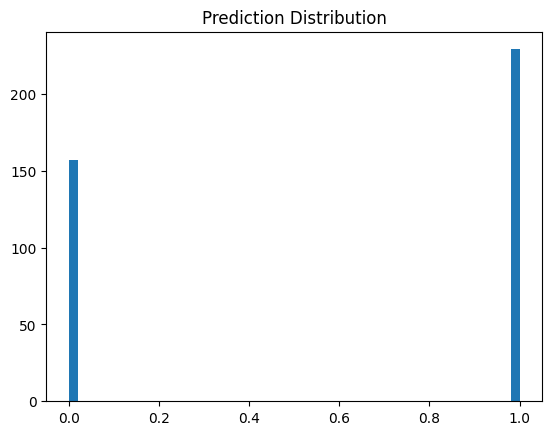

In [39]:
plt.hist(preds, bins=50)
plt.title("Prediction Distribution")
plt.show()

In [40]:
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.layers import GlobalAveragePooling2D
from tensorflow.keras.models import Model

In [49]:
base_model = MobileNetV2(
    weights='imagenet',
    include_top=False,
    input_shape=(224,224,3)
)

base_model.trainable = False

In [50]:
x = base_model.output

x = GlobalAveragePooling2D()(x)

x = Dense(128, activation='relu')(x)

x = Dropout(0.5)(x)

output = Dense(1, activation='sigmoid')(x)

mobilenet = Model(
    inputs=base_model.input,
    outputs=output
)

In [51]:
mobilenet.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

mobilenet.summary()

Model: "functional_11"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_2       │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Conv1 (Conv2D)      │ (None, 112, 112,  │        864 │ input_layer_2[0]… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bn_Conv1            │ (None, 112, 112,  │        128 │ Conv1[0][0]       │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Conv1_relu (ReLU)   │ (None, 112, 112,  │          0 │ bn_Conv1[0][0]    │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │        288 │ Conv1_relu[0][0]  │
│ (DepthwiseConv2D)   │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │        128 │ expanded_conv_de… │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │          0 │ expanded_conv_de… │
│ (ReLU)              │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_proj… │ (None, 112, 112,  │        512 │ expanded_conv_de… │
│ (Conv2D)            │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_proj… │ (None, 112, 112,  │         64 │ expanded_conv_pr… │
│ (BatchNormalizatio… │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand      │ (None, 112, 112,  │      1,536 │ expanded_conv_pr… │
│ (Conv2D)            │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand_BN   │ (None, 112, 112,  │        384 │ block_1_expand[0… │
│ (BatchNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand_relu │ (None, 112, 112,  │          0 │ block_1_expand_B… │
│ (ReLU)              │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_pad         │ (None, 113, 113,  │          0 │ block_1_expand_r… │
│ (ZeroPadding2D)     │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise   │ (None, 56, 56,    │        864 │ block_1_pad[0][0] │
│ (DepthwiseConv2D)   │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise_… │ (None, 56, 56,    │        384 │ block_1_depthwis… │
│ (BatchNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise_… │ (None, 56, 56,    │          0 │ block_1_depthwis… │
│ (ReLU)              │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_project     │ (None, 56, 56,    │      2,304 │ block_1_depthwis

 Total params: 2,422,081 (9.24 MB)

 Trainable params: 164,097 (641.00 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [52]:
from tensorflow.keras.callbacks import EarlyStopping

early_stop = EarlyStopping(
    monitor='val_loss',
    patience=5,
    min_delta=1e-5,
    restore_best_weights=True
)

history_mobilenet = mobilenet.fit(
    train_generator,
    validation_data=test_generator,
    epochs=100,
    callbacks=[early_stop]
)

Epoch 1/100
49/49 ━━━━━━━━━━━━━━━━━━━━ 61s 1s/step - accuracy: 0.9577 - loss: 0.1010 - val_accuracy: 1.0000 - val_loss: 0.0012
Epoch 2/100
49/49 ━━━━━━━━━━━━━━━━━━━━ 50s 1s/step - accuracy: 0.9980 - loss: 0.0072 - val_accuracy: 1.0000 - val_loss: 6.2245e-04
Epoch 3/100
49/49 ━━━━━━━━━━━━━━━━━━━━ 47s 962ms/step - accuracy: 1.0000 - loss: 0.0015 - val_accuracy: 1.0000 - val_loss: 3.2000e-04
Epoch 4/100
49/49 ━━━━━━━━━━━━━━━━━━━━ 47s 942ms/step - accuracy: 1.0000 - loss: 0.0010 - val_accuracy: 1.0000 - val_loss: 1.4826e-04
Epoch 5/100
49/49 ━━━━━━━━━━━━━━━━━━━━ 46s 940ms/step - accuracy: 1.0000 - loss: 0.0011 - val_accuracy: 1.0000 - val_loss: 8.9888e-05
Epoch 6/100
49/49 ━━━━━━━━━━━━━━━━━━━━ 46s 936ms/step - accuracy: 1.0000 - loss: 7.4989e-04 - val_accuracy: 1.0000 - val_loss: 1.1312e-04
Epoch 7/100
49/49 ━━━━━━━━━━━━━━━━━━━━ 45s 917ms/step - accuracy: 1.0000 - loss: 3.8365e-04 - val_accuracy: 1.0000 - val_loss: 7.5754e-05
Epoch 8/100
49/49 ━━━━━━━━━━━━━━━━━━━━ 45s 918ms/step - accuracy

In [53]:
test_loss, test_acc = mobilenet.evaluate(test_generator)
print("MobileNetV2 Accuracy:", test_acc)

13/13 ━━━━━━━━━━━━━━━━━━━━ 8s 593ms/step - accuracy: 1.0000 - loss: 1.7198e-05
MobileNetV2 Accuracy: 1.0


13/13 ━━━━━━━━━━━━━━━━━━━━ 10s 683ms/step
📋 CLASSIFICATION REPORT


,precision,recall,f1-score,support
Non-PCOS,1.000000,1.000000,1.000000,157.000000
PCOS,1.000000,1.000000,1.000000,229.000000
accuracy,1.000000,1.000000,1.000000,1.000000
macro avg,1.000000,1.000000,1.000000,386.000000
weighted avg,1.000000,1.000000,1.000000,386.000000




 CONFUSION MATRIX


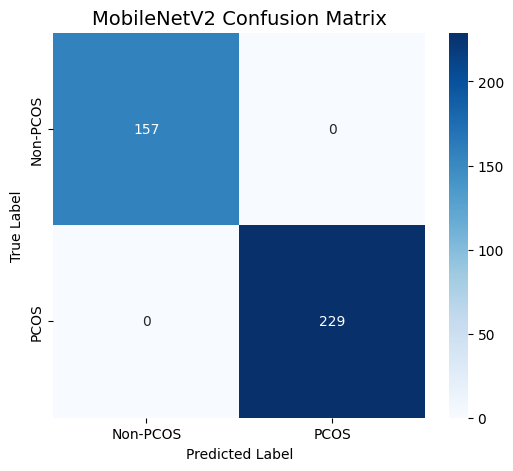

In [54]:
import numpy as np
from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix

preds = mobilenet.predict(test_generator)

preds = (preds > 0.5).astype(int)

y_true = test_generator.classes

print("📋 CLASSIFICATION REPORT")
report = pd.DataFrame(
    classification_report(
        y_true,
        preds,
        target_names=["Non-PCOS", "PCOS"],
        output_dict=True
    )
).transpose()

display(report.style.background_gradient())

print("\n\n CONFUSION MATRIX")
cm = confusion_matrix(y_true, preds)

plt.figure(figsize=(6,5))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Non-PCOS', 'PCOS'],
    yticklabels=['Non-PCOS', 'PCOS']
)

plt.title("MobileNetV2 Confusion Matrix", fontsize=14)
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.show()

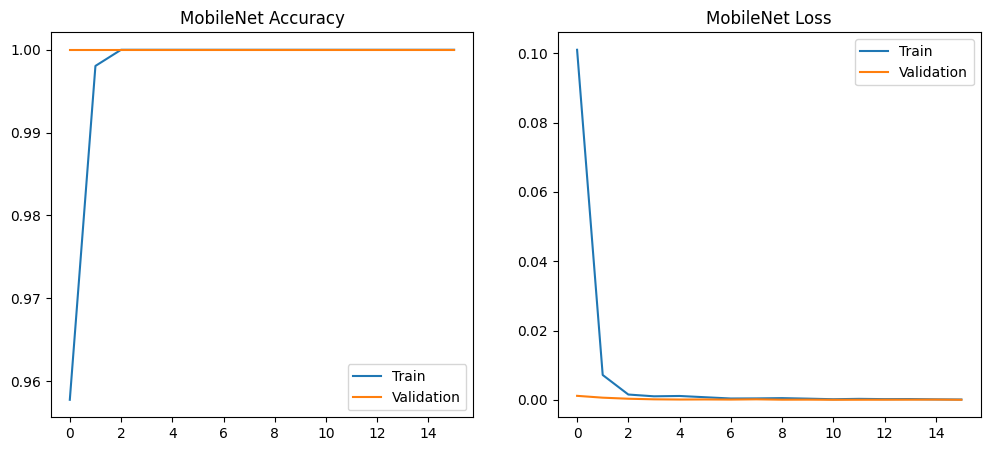

In [55]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12,5))

plt.subplot(1,2,1)
plt.plot(history_mobilenet.history['accuracy'])
plt.plot(history_mobilenet.history['val_accuracy'])
plt.title("MobileNet Accuracy")
plt.legend(['Train','Validation'])

plt.subplot(1,2,2)
plt.plot(history_mobilenet.history['loss'])
plt.plot(history_mobilenet.history['val_loss'])
plt.title("MobileNet Loss")
plt.legend(['Train','Validation'])

plt.show()

## Save best model (MobileNetV2)

Both CNN and MobileNetV2 achieved 100% performance on the PCOS ultrasound dataset. However, MobileNetV2 trained faster because it uses a pre-trained model and required less computational effort. Therefore, MobileNetV2 was selected as the final model for PCOS ultrasound image classification.

In [56]:
# Save the trained MobileNetV2 model
mobilenet.save("PCOS_MobileNetV2.keras")

print("MobileNetV2 model saved successfully!")

MobileNetV2 model saved successfully!


In [57]:
import os

if os.path.exists("PCOS_MobileNetV2.keras"):
    print("Model file exists!")
    print("File size:", round(os.path.getsize("PCOS_MobileNetV2.keras") / (1024 * 1024), 2), "MB")

Model file exists!
File size: 11.05 MB


In [58]:
from tensorflow.keras.models import load_model

saved_model = load_model("PCOS_MobileNetV2.keras")

print("Model loaded successfully!")

Model loaded successfully!


In [59]:
import os

print(os.listdir("/kaggle/working"))

['.virtual_documents', 'fresh_split', 'PCOS_MobileNetV2.keras', 'clean_data']
